# 07. Optimización predictiva de Lending Club

**Objetivo:** mejorar el ordenamiento del riesgo de incumplimiento del CatBoost de la fase 2, mediante datos de entrenamiento, variables, preparación, hiperparámetros y combinaciones de modelos. Esta es una bitácora reproducible de investigación y resultados; no constituye el informe final del curso.

La clase positiva es **Charged Off** y la negativa **Fully Paid**. El alcance son préstamos **aceptados, a 36 meses, con desenlace conocido**. Los préstamos activos no se etiquetan como pagados ni como incumplidos. Tampoco se extrapolan los resultados a solicitantes rechazados.

La métrica principal es **Average Precision (AP)** sobre las puntuaciones originales (`raw_AP`). AP resume qué tan bien aparecen los incumplimientos al principio del ranking. No es el porcentaje de préstamos correctamente clasificados. La evaluación siempre utiliza las mismas filas dentro de cada comparación; la prevalencia del incumplimiento afecta AP.

**Límite de independencia:** 2015 y 2016 ya se observaron en fases anteriores. Son benchmarks temporales reutilizados. Congelar esta nueva selección antes de generar sus predicciones evita reajustarla con estos resultados, pero no convierte los años conocidos en una nueva prueba independiente.

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'experiments' / 'protocol_v3.json').exists())
OUT = ROOT / 'outputs/research_v3'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'savefig.facecolor': 'white'})
COLORS = {'positive': '#176D78', 'negative': '#B75335',
          'reference': '#64748B', 'secondary': '#7962A5'}
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

def read_json(name, default=None):
    path = OUT / name
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else default

def read_table(name):
    path = OUT / name
    if not path.exists() or path.stat().st_size == 0:
        print(f'No se generó el artefacto opcional {name}.')
        return pd.DataFrame()
    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()

def show_columns(frame, names):
    display(frame[[name for name in names if name in frame]].copy())

def ap_column(frame):
    return 'raw_AP' if 'raw_AP' in frame else 'AP'

def cohort_year(frame):
    return frame['cohort'].astype(str).str.extract(r'(20\d{2})', expand=False)

def save_show(fig, name, layout_rect=None):
    fig.tight_layout(rect=layout_rect)
    fig.savefig(FIG / name, dpi=170, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def choose_model(frame, choices, description):
    names = set(frame['model'].astype(str))
    match = next((name for name in choices if name in names), None)
    if match is None:
        raise ValueError(f'No se identificó {description}; modelos disponibles: {sorted(names)}')
    return match

protocol = json.loads((ROOT / 'experiments' / 'protocol_v3.json').read_text(encoding='utf-8'))
selection = read_json('selection.json', {})
benchmark = read_table('benchmark_metrics.csv')
assert not benchmark.empty, 'Primero debe concluir la evaluación registrada.'
reference_name = choose_model(benchmark,
    ['v2_frozen'],
    'el CatBoost V2 congelado')
selected_name = choose_model(benchmark,
    ['selected', 'v3_selected', 'selected_v3', selection.get('selected', '')],
    'la estrategia seleccionada en desarrollo')
benchmark['year'] = cohort_year(benchmark)
primary = benchmark.loc[benchmark['year'].eq('2015')].copy()
assert primary['n'].eq(258856).all(), 'La comparación principal debe conservar los 258.856 IDs.'
assert primary['model'].nunique() == len(primary), 'Debe existir una fila por modelo en 2015.'
print('Estrategia elegida en desarrollo:', selection.get('selected'))
print('Referencia congelada:', reference_name)
print('Evaluación principal: mismos 258.856 préstamos de 2015 a 36 meses.')
print('No se ha creado una prueba final independiente nueva.')

Estrategia elegida en desarrollo: catboost_combined_control
Referencia congelada: v2_frozen
Evaluación principal: mismos 258.856 préstamos de 2015 a 36 meses.
No se ha creado una prueba final independiente nueva.


## 1. Diseño temporal y comparabilidad

La búsqueda usa dos cortes retrospectivos: entrenar hasta junio de 2013 y validar julio–diciembre de 2013; entrenar hasta diciembre de 2013 y validar enero–junio de 2014. Cada corte conserva sus IDs de validación entre configuraciones. Se limita el entrenamiento de búsqueda a 60.000 filas y la validación a 20.000 por corte, con semilla fija.

Los candidatos promovidos se entrenan hasta junio de 2014 y se comparan en **todo 2014 Q3**. Ese bloque elige el modelo y los pesos de los ensambles. La elección no utiliza las nuevas predicciones de 2015/2016.

El entrenamiento definitivo de V3 llega a **noviembre de 2014**. En la receta que comienza en 2012, esto incorpora **43.146 préstamos** frente al entrenamiento V2 que terminaba en septiembre. Un control conserva los parámetros y variables de V2 y cambia las fechas de entrenamiento para separar parte del aporte de más datos del aporte de nuevas configuraciones. Las recetas que comienzan en 2013 tienen su propio tamaño.

Diciembre de 2014 se divide determinísticamente por la paridad de SHA256 del ID: una mitad calibra probabilidades y la otra fija umbrales. Son grupos disjuntos del **mismo mes**, no dos subperíodos cronológicos. El calibrador sigmoide exige pendiente positiva para conservar el ranking; la selección principal usa siempre puntuaciones sin calibrar.

Las fechas de emisión no reconstruyen cuándo se conoció históricamente cada desenlace. Este diseño permite contrastar cohortes, pero no simula completamente una decisión en tiempo real.

In [2]:
display(pd.DataFrame(protocol['cv']))
display(pd.DataFrame([
    {'etapa': 'Selección de candidatos', 'entrenamiento_hasta': protocol['candidate_training_end'],
     'evaluación_desde': protocol['selection_start'], 'evaluación_hasta': protocol['selection_end']},
    {'etapa': 'Modelo definitivo + calibración / umbral', 'entrenamiento_hasta': protocol['final_training_end'],
     'evaluación_desde': protocol['calibration_start'], 'evaluación_hasta': protocol['calibration_end']},
]))
context_manifest = read_json('context_manifest.json', {})
if context_manifest:
    display(pd.Series(context_manifest, name='Trazabilidad del contexto de solicitud'))
training_manifest = read_json('training_manifest.json', {})
if training_manifest:
    training_table = pd.DataFrame.from_dict(training_manifest, orient='index')
    show_columns(training_table, ['train_n', 'train_start', 'train_end', 'train_ids_sha256'])
calibration_split = read_json('calibration_split.json', {})
if calibration_split:
    display(pd.Series(calibration_split, name='Partición de diciembre'))
calibration = read_table('calibration_selection.csv')
if not calibration.empty:
    display(calibration)

,train_end,validation_start,validation_end
0,2013-06-30,2013-07-01,2013-12-31
1,2013-12-31,2014-01-01,2014-06-30


,etapa,entrenamiento_hasta,evaluación_desde,evaluación_hasta
0,Selección de candidatos,2014-06-30,2014-07-01,2014-09-30
1,Modelo definitivo + calibración / umbral,2014-11-30,2014-12-01,2014-12-31


created_utc                                                                    2026-11-02T20:51:10.491958+00:00
source_sha256                                  55c16f75120f897683f02e7aabcf080d0e4a20c4832feb1d592cfa941bd62a2d
cache_sha256                                   7213ae618c0c62d233669ac250ea62171fe23c2ae667cd7a2bdc9b1c2e64c77e
rows                                                                                                    1062662
ids_sha256                                     48dd77ce693187c2bf19ef9344de2ef32ffc97dc072f83bbfc8c7c1b69f479ae
fields                                                                                    [emp_title, zip_code]
labels_extracted                                                                                          False
purpose             Application fields only; joining evaluation inputs does not use their labels for selection.
Name: Trazabilidad del contexto de solicitud, dtype: object

,train_n,train_start,train_end,train_ids_sha256
catboost_combined_control,299588,2012-01-01,2014-11-01,5029ff8b2a4bcae1de24e2cd8e5106d78b19941cb920756b063577cb0ad29b81
catboost_joint,299588,2012-01-01,2014-11-01,5029ff8b2a4bcae1de24e2cd8e5106d78b19941cb920756b063577cb0ad29b81
lightgbm_joint,299588,2012-01-01,2014-11-01,5029ff8b2a4bcae1de24e2cd8e5106d78b19941cb920756b063577cb0ad29b81
logistic_joint,256118,2013-01-01,2014-11-01,12167310b3185f1f1967f10c12e66d22214e082bf6866b43890505c9b73b075c
svm_linear_joint,299588,2012-01-01,2014-11-01,5029ff8b2a4bcae1de24e2cd8e5106d78b19941cb920756b063577cb0ad29b81
svm_nystroem_joint,256118,2013-01-01,2014-11-01,12167310b3185f1f1967f10c12e66d22214e082bf6866b43890505c9b73b075c
v2_catboost,299588,2012-01-01,2014-11-01,5029ff8b2a4bcae1de24e2cd8e5106d78b19941cb920756b063577cb0ad29b81
xgboost_joint,299588,2012-01-01,2014-11-01,5029ff8b2a4bcae1de24e2cd8e5106d78b19941cb920756b063577cb0ad29b81


rule                      SHA256(str(id), UTF-8) parity: even calibration, odd policy; same month, disjoint groups
calibration_n                                                                                                 3371
policy_n                                                                                                      3503
december_n                                                                                                    6874
calibration_ids_sha256                            e11ea5fa635fd043e5974730d3354f0146558399bc34eb8e33ce4a33c51affae
policy_ids_sha256                                 9dd4f72920d622e72727b975793220a6bab0e6f33d20ddd7a60e5889bedadc0e
december_ids_sha256                               564e034bce989bcd1c25686e9cf5fad1b7bb1062893655fafbf97970e20c34c9
overlap_n                                                                                                        0
Name: Partición de diciembre, dtype: object

,model,method,calibration_n,sigmoid_slope,sigmoid_intercept,n,positive_n,prevalence,AP,ROC_AUC,...,threshold,flag_rate,FPR,FNR,KS,recall_at_top20,precision_at_top20,raw_AP,raw_ROC_AUC,calibration_AP_preserved
0,catboost_combined_control,positive_sigmoid,3371,1.096570,0.175113,3503,491,0.140166,0.281141,0.707184,...,0.159726,0.328576,0.287185,0.417515,0.311099,0.399185,0.279601,0.281141,0.707184,True
1,catboost_joint,positive_sigmoid,3371,1.139414,0.269655,3503,491,0.140166,0.277813,0.702253,...,0.177776,0.263203,0.225432,0.505092,0.303775,0.391039,0.273894,0.277813,0.702253,True
2,lightgbm_joint,positive_sigmoid,3371,1.057146,0.127194,3503,491,0.140166,0.289415,0.705427,...,0.151004,0.343134,0.303121,0.411405,0.307120,0.397149,0.278174,0.289415,0.705427,True
3,logistic_joint,positive_sigmoid,3371,0.969604,-0.017419,3503,491,0.140166,0.282951,0.702547,...,0.154074,0.336283,0.294821,0.409369,0.297853,0.399185,0.279601,0.282951,0.702547,True
4,svm_linear_joint,positive_sigmoid,3371,2.121787,-1.829863,3503,491,0.140166,0.280582,0.702713,...,0.143408,0.384528,0.342961,0.360489,0.296550,0.395112,0.276748,0.280582,0.702713,True
5,svm_nystroem_joint,positive_sigmoid,3371,3.966861,0.926798,3503,491,0.140166,0.280178,0.707051,...,0.139890,0.353982,0.312417,0.391039,0.309023,0.399185,0.279601,0.280178,0.707051,True
6,v2_catboost,positive_sigmoid,3371,1.117880,0.229507,3503,491,0.140166,0.281242,0.705674,...,0.162536,0.311162,0.270584,0.439919,0.302651,0.393075,0.275321,0.281242,0.705674,True
7,xgboost_joint,positive_sigmoid,3371,1.088096,-0.561218,3503,491,0.140166,0.283588,0.707203,...,0.196636,0.209535,0.172643,0.564155,0.302933,0.421589,0.295292,0.283588,0.707203,True


## 2. Qué se cambia y qué información se permite

| Componente | Hipótesis contrastada | Control frente a fuga de información |
|---|---|---|
| Datos de entrenamiento | Empezar en 2012 o 2013; dar distinto peso a préstamos recientes | La validación no cambia ni recibe ponderaciones de entrenamiento |
| Relaciones financieras | La capacidad disponible, composición de cuentas y carga relativa pueden añadir señal | Solo montos y variables del bureau observables al originar el préstamo |
| Contexto de solicitud | Cargo/empleador declarado y área postal de tres dígitos pueden aportar contexto | Vocabulario, categorías raras y frecuencias se aprenden sin etiquetas y solo en entrenamiento |
| Preparación por algoritmo | Los métodos lineales y kernels necesitan escalado; los árboles toleran faltantes de otra forma | Medianas, cuantiles y codificadores se ajustan exclusivamente en entrenamiento |
| Hiperparámetros y ensambles | Regularización, capacidad y errores complementarios pueden mejorar AP | Configuraciones y pesos se eligen en desarrollo |

Las veinte relaciones financieras nuevas incluyen préstamo/crédito disponible, cuentas activas/cuentas abiertas, morosidad histórica/cuentas totales y préstamo/ingreso residual estimado. Los denominadores inválidos producen faltantes, no infinitos. El indicador que suma DTI y amortización de principal es una **aproximación sin intereses**, no la cuota contractual.

Se excluyen `grade`, `sub_grade`, `int_rate`, `installment`, pagos, recuperaciones, FICO posterior y datos de acuerdos de pago. Esto mantiene el objetivo de predecir desde la información de solicitud/bureau sin aprovechar la calificación o el precio ya asignados por Lending Club. El código también descarta columnas constantes o con más de 95% de ausencia en el entrenamiento correspondiente.

El [contrato completo de las 24 variables nuevas](../experiments/feature_contract_v3.csv) registra entradas, fórmula y limitación de disponibilidad. A continuación se muestran cinco ejemplos. Un nombre intuitivo no sustituye su definición: el ingreso residual y el saldo hipotecario inferido son aproximaciones, y `emp_title` puede representar empleador o cargo según la cohorte. Una tasa baja de faltantes no garantiza que el significado del texto permanezca estable.

In [3]:
contract = pd.read_csv(ROOT / 'experiments' / 'feature_contract_v3.csv')
intuitive = ['v3_loan_to_available_revolving', 'v3_active_revolving_share',
             'v3_loan_to_annual_free_income', 'v3_principal_burden_plus_dti',
             'v3_emp_title_category']
display(contract.set_index('name').loc[intuitive].reset_index())
if (OUT / 'context_availability.csv').exists():
    print('Disponibilidad del contexto en desarrollo: préstamos a 36 meses de 2012–2014.')
    display(read_table('context_availability.csv'))
if (OUT / 'context_shift.csv').exists():
    print('Cambio entre entrenamiento y validación en los cortes de desarrollo.')
    context_shift = read_table('context_shift.csv')
    show_columns(context_shift, ['fold', 'field', 'train_start', 'train_end',
        'validation_start', 'validation_end', 'train_n', 'validation_n',
        'retained_category_n', 'train_missing_rate', 'validation_missing_rate',
        'validation_unseen_nonmissing_rate', 'validation_known_rare_rate',
        'validation_retained_category_rate', 'total_variation_distance'])
    print('Faltantes, textos no vistos, categorías raras conocidas y categorías retenidas usan todas las filas de validación como denominador.')
    print('La distancia de variación total describe cambios de distribución; no demuestra una causa ni fecha por sí sola un cambio de esquema.')

,name,inputs,formula_meaning_es,availability_limitation_es
0,v3_loan_to_available_revolving,loan_amnt; total_rev_hi_lim; revol_bal,"Monto solicitado / max(límite revolvente − saldo revolvente, 0).",Disponibilidad cero o inválida produce faltante. El crédito disponible es aproximado a partir de...
1,v3_active_revolving_share,num_actv_rev_tl; num_op_rev_tl,Número de cuentas revolventes activas / número de cuentas revolventes abiertas.,Requiere cuentas abiertas positivas. Las definiciones de activa y abierta provienen del bureau; ...
2,v3_loan_to_annual_free_income,loan_amnt; annual_inc; dti,Monto solicitado / [ingreso anual × (1 − DTI / 100)]. Aproxima el tamaño del préstamo frente al ...,El denominador debe ser positivo; DTI de 100% o más produce faltante. No es ingreso disponible o...
3,v3_principal_burden_plus_dti,loan_amnt; term; annual_inc; dti,[(monto solicitado / meses del plazo) / (ingreso anual / 12)] + DTI / 100. Suma una amortización...,Es una aproximación de principal solamente: excluye intereses y no equivale a installment ni a l...
4,v3_emp_title_category,emp_title,"Texto en minúsculas, sin puntuación y con espacios normalizados; categoría retenida si aparece a...",El campo puede describir empleador o cargo según la cohorte y cambiar de significado con el tiem...


Disponibilidad del contexto en desarrollo: préstamos a 36 meses de 2012–2014.


,year,field,n,missing_n,missing_rate,unique_nonmissing_normalized,unique_fraction_nonmissing
0,2012,emp_title,43470,2789,0.064159,30367,0.746466
1,2012,zip_code,43470,0,0.000000,789,0.018150
2,2013,emp_title,100422,7098,0.070682,57925,0.620687
3,2013,zip_code,100422,0,0.000000,833,0.008295
4,2014,emp_title,162570,10628,0.065375,43836,0.288505
5,2014,zip_code,162570,0,0.000000,854,0.005253


Cambio entre entrenamiento y validación en los cortes de desarrollo.


,fold,field,train_start,train_end,validation_start,validation_end,train_n,validation_n,retained_category_n,train_missing_rate,validation_missing_rate,validation_unseen_nonmissing_rate,validation_known_rare_rate,validation_retained_category_rate,total_variation_distance
0,1,emp_title,2012-01-01,2013-06-30,2013-07-01,2013-12-31,60000,20000,29,0.065633,0.070700,0.741450,0.168150,0.019700,0.817467
1,1,zip_code,2012-01-01,2013-06-30,2013-07-01,2013-12-31,60000,20000,330,0.000000,0.000000,0.000300,0.184850,0.814850,0.092783
2,1,emp_title,2013-01-01,2013-06-30,2013-07-01,2013-12-31,41124,20000,13,0.066822,0.070700,0.777750,0.138500,0.013050,0.820408
3,1,zip_code,2013-01-01,2013-06-30,2013-07-01,2013-12-31,41124,20000,244,0.000000,0.000000,0.000900,0.267650,0.731450,0.085020
4,2,emp_title,2012-01-01,2013-12-31,2014-01-01,2014-06-30,60000,20000,30,0.067433,0.072300,0.360800,0.427500,0.139400,0.807550
5,2,zip_code,2012-01-01,2013-12-31,2014-01-01,2014-06-30,60000,20000,324,0.000000,0.000000,0.002000,0.200300,0.797700,0.099250
6,2,emp_title,2013-01-01,2013-12-31,2014-01-01,2014-06-30,60000,20000,43,0.070683,0.072300,0.337400,0.410600,0.179700,0.748983
7,2,zip_code,2013-01-01,2013-12-31,2014-01-01,2014-06-30,60000,20000,331,0.000000,0.000000,0.001800,0.192800,0.805400,0.087400


Faltantes, textos no vistos, categorías raras conocidas y categorías retenidas usan todas las filas de validación como denominador.
La distancia de variación total describe cambios de distribución; no demuestra una causa ni fecha por sí sola un cambio de esquema.


## 3. Contrastes individuales y cambio combinado

El bloque mantiene los parámetros V2 de LightGBM y las mismas filas de validación, sin parada anticipada. Incluye una referencia, seis contrastes que cambian **un factor a la vez** y la opción `combined`, que incorpora simultáneamente las relaciones financieras y el contexto. Los contrastes individuales permiten medir cada cambio respecto a la base. El resultado de `combined` corresponde al cambio conjunto de esos dos grupos y no se atribuye a una sola intervención.

Una ganancia media puede ocultar que un período mejora y otro empeora. Por eso se conservan AP por corte, su diferencia frente a la base y los resultados negativos. Estas diferencias son descriptivas de los cortes utilizados; no prueban causalidad.

,name,CV_AP,delta_AP,fold1_AP,fold2_AP
0,baseline,0.222613,0.000000,0.214900,0.230326
7,recency24,0.222422,-0.000191,0.213821,0.231024
1,financial,0.221962,-0.000651,0.215281,0.228644
4,clipping,0.221238,-0.001375,0.213153,0.229324
6,recency12,0.220620,-0.001993,0.211813,0.229428
5,from_2013,0.219008,-0.003605,0.211980,0.226037
3,combined,0.213912,-0.008701,0.204207,0.223617
2,context,0.211609,-0.011004,0.201752,0.221467


,name,delta_AP,fold1_delta_AP,fold2_delta_AP,mejora_en_todos_los_cortes
0,baseline,0.000000,0.000000,0.000000,False
1,financial,-0.000651,0.000381,-0.001682,False
2,context,-0.011004,-0.013148,-0.008860,False
3,combined,-0.008701,-0.010693,-0.006709,False
4,clipping,-0.001375,-0.001747,-0.001002,False
5,from_2013,-0.003605,-0.002920,-0.004289,False
6,recency12,-0.001993,-0.003087,-0.000898,False
7,recency24,-0.000191,-0.001079,0.000697,False


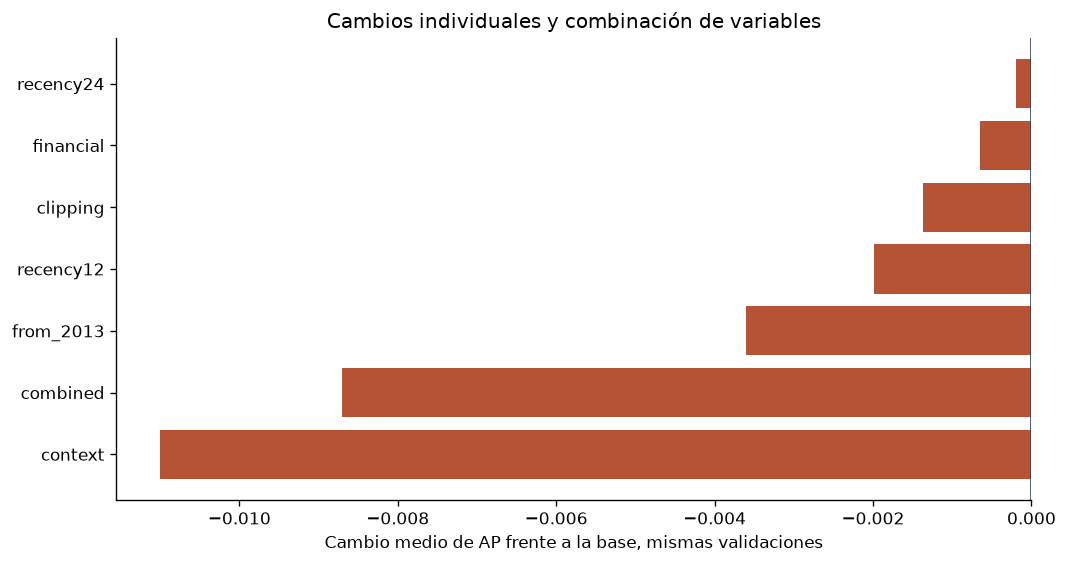

In [4]:
ablations = read_table('ablations.csv')
if not ablations.empty:
    display(ablations.sort_values('CV_AP', ascending=False))
    base = ablations.loc[ablations['name'].eq('baseline')].iloc[0]
    delta_columns = []
    for col in [c for c in ablations if c.startswith('fold') and c.endswith('_AP')]:
        delta_col = col.replace('_AP', '_delta_AP')
        ablations[delta_col] = ablations[col] - base[col]
        delta_columns.append(delta_col)
    ablations['mejora_en_todos_los_cortes'] = ablations[delta_columns].gt(0).all(axis=1)
    show_columns(ablations, ['name', 'delta_AP', *delta_columns, 'mejora_en_todos_los_cortes'])
    ordered = ablations.loc[~ablations['name'].eq('baseline')].sort_values('delta_AP')
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.barh(ordered['name'], ordered['delta_AP'],
            color=[COLORS['positive'] if x > 0 else COLORS['negative'] for x in ordered['delta_AP']])
    ax.axvline(0, color='#334155', linewidth=1)
    ax.set(xlabel='Cambio medio de AP frente a la base, mismas validaciones',
           title='Cambios individuales y combinación de variables')
    save_show(fig, '01_ablaciones.png')

## 4. Búsqueda conjunta y preparación específica

Se ajustan **CatBoost, LightGBM, XGBoost, regresión logística, SVM lineal y Nyström RBF + SVM lineal**. Nyström aproxima el kernel; no es una SVC RBF exacta. La SVC RBF exacta ya se contrastó en la fase 2 con un presupuesto más reducido y no se repite aquí como si fuera un experimento nuevo.

CatBoost trabaja con categorías nativas. LightGBM y XGBoost reciben categorías codificadas con un vocabulario aprendido en entrenamiento. Regresión logística y SVM incorporan imputación, escalado y codificación de categorías; una variante comprime magnitudes monetarias y recorta extremos con cuantiles del entrenamiento. `C` controla la regularización de los métodos lineales; `gamma` y el número de componentes controlan la aproximación RBF.

La búsqueda combina estos cambios con los hiperparámetros y la receta temporal. Los árboles usan AP como criterio de parada anticipada sobre una validación sin ponderar. **AP no debe confundirse con un área trapezoidal interpolada bajo la curva precisión–recall.** Los pesos de clase o de recencia afectan el entrenamiento, no redefinen la población de evaluación.

Los intentos podados y fallidos permanecen registrados. Un intento podado puede tener solo un corte y su valor parcial no se compara como si fuera el promedio final de los dos cortes. La búsqueda es finita y condicionada al presupuesto; no demuestra un óptimo global.

**Cobertura adicional de preparación:** los **46 intentos HPO originales** finalizaron, pero los cuatro intentos de cada familia lineal/kernel usaron `native`; el muestreo no llegó a evaluar `log_clip` en ellas. Antes de abrir nuevas predicciones de benchmark se registraron [tres comparaciones adicionales de desarrollo](../experiments/preparation_followup_v3.json), una para regresión logística, SVM lineal y Nyström. Cada comparación conserva la mejor configuración HPO original de su familia y cambia únicamente la preparación a `log_clip`, sobre los mismos dos cortes e IDs.

Se promueve la opción con mayor AP media al puesto de candidato Q3 ya reservado a esa familia, sin añadir puestos ni pesos de ensamble. Los resultados y fallos se conservan. La diferencia mide el **tratamiento conjunto de recorte y transformación logarítmica**, no el aporte aislado de cada operación. Una media positiva no implica que ambos cortes mejoren: se muestran las diferencias individuales después de comprobar los mismos IDs de entrenamiento y validación. Son tres pruebas adaptativas adicionales, separadas del conteo de 46 intentos originales; tampoco constituyen confirmación independiente.

state,COMPLETE,PRUNED
family,,
catboost,5,1
lightgbm,10,6
logistic,4,0
svm_linear,4,0
svm_nystroem,4,0
xgboost,9,3


Intentos HPO originales registrados: 46 ; completos: 36


,family,number,state,value,duration,params_feature_mode,params_preparation,params_start,params_half_life
7,lightgbm,7,PRUNED,0.210812,0 days 00:00:11.641901,financial,native,2012-01-01,12
8,lightgbm,8,PRUNED,0.212408,0 days 00:00:16.963357,financial,native,2012-01-01,12
10,lightgbm,10,PRUNED,0.213084,0 days 00:00:13.244329,financial,native,2013-01-01,12
13,lightgbm,13,PRUNED,0.213880,0 days 00:00:14.555210,financial,native,2012-01-01,12
14,lightgbm,14,PRUNED,0.198909,0 days 00:00:21.822981,context,native,2012-01-01,24
15,lightgbm,15,PRUNED,0.221481,0 days 00:00:43.833072,financial,native,2012-01-01,12
21,catboost,5,PRUNED,0.211018,0 days 00:01:18.154926,baseline,native,2012-01-01,0
28,xgboost,6,PRUNED,0.196353,0 days 00:01:22.467217,context,native,2012-01-01,0
30,xgboost,8,PRUNED,0.208964,0 days 00:00:26.510993,baseline,native,2013-01-01,0
32,xgboost,10,PRUNED,0.210185,0 days 00:00:26.353511,baseline,native,2012-01-01,0


Mejores intentos de la búsqueda HPO original; las comparaciones adicionales de preparación se muestran por separado.


,family,rank,trial,CV_AP,feature_mode,preparation,start,half_life,params,fold_AP
2,catboost,1,0,0.223986,baseline,native,2012-01-01,0,"{'iterations': 1400, 'learning_rate': 0.02205578452420942, 'depth': 7, 'l2_leaf_reg': 54.1299336...","[0.2163242043612846, 0.23164752135593641]"
4,xgboost,1,0,0.223459,baseline,native,2012-01-01,0,"{'n_estimators': 1600, 'learning_rate': 0.04676664740057031, 'max_depth': 3, 'min_child_weight':...","[0.21661480817569775, 0.2303039767206505]"
0,lightgbm,1,2,0.223239,financial,native,2012-01-01,12,"{'n_estimators': 1800, 'learning_rate': 0.02588968965098415, 'num_leaves': 15, 'min_child_sample...","[0.21627778803326056, 0.23019999709432226]"
10,svm_nystroem,1,3,0.220334,financial,native,2013-01-01,12,"{'C': 2.273843986004399, 'class_weight': None, 'gamma': 0.0006438036013348905, 'n_components': 600}","[0.21415321818476865, 0.22651449844464971]"
6,logistic,1,3,0.218977,financial,native,2013-01-01,12,"{'C': 2.273843986004399, 'class_weight': None}","[0.21371658713001843, 0.22423811571474223]"
8,svm_linear,1,2,0.218079,financial,native,2012-01-01,12,"{'C': 0.0030605882806936423, 'class_weight': 'balanced'}","[0.21318286665664354, 0.22297527021907682]"
3,catboost,2,2,0.223387,financial,native,2012-01-01,12,"{'iterations': 1400, 'learning_rate': 0.02205578452420942, 'depth': 7, 'l2_leaf_reg': 54.1299336...","[0.21729315316956027, 0.22948051934725955]"
1,lightgbm,2,0,0.222597,baseline,native,2012-01-01,0,"{'n_estimators': 1800, 'learning_rate': 0.02588968965098415, 'num_leaves': 15, 'min_child_sample...","[0.2154517785397429, 0.22974205042900062]"
5,xgboost,2,2,0.222519,financial,native,2012-01-01,12,"{'n_estimators': 1600, 'learning_rate': 0.04676664740057031, 'max_depth': 3, 'min_child_weight':...","[0.21723111010588572, 0.2278071140334808]"
11,svm_nystroem,2,2,0.220302,financial,native,2012-01-01,12,"{'C': 1.2649675876166606, 'class_weight': None, 'gamma': 0.0009187608485161292, 'n_components': ...","[0.21417518515642975, 0.22642807181519983]"


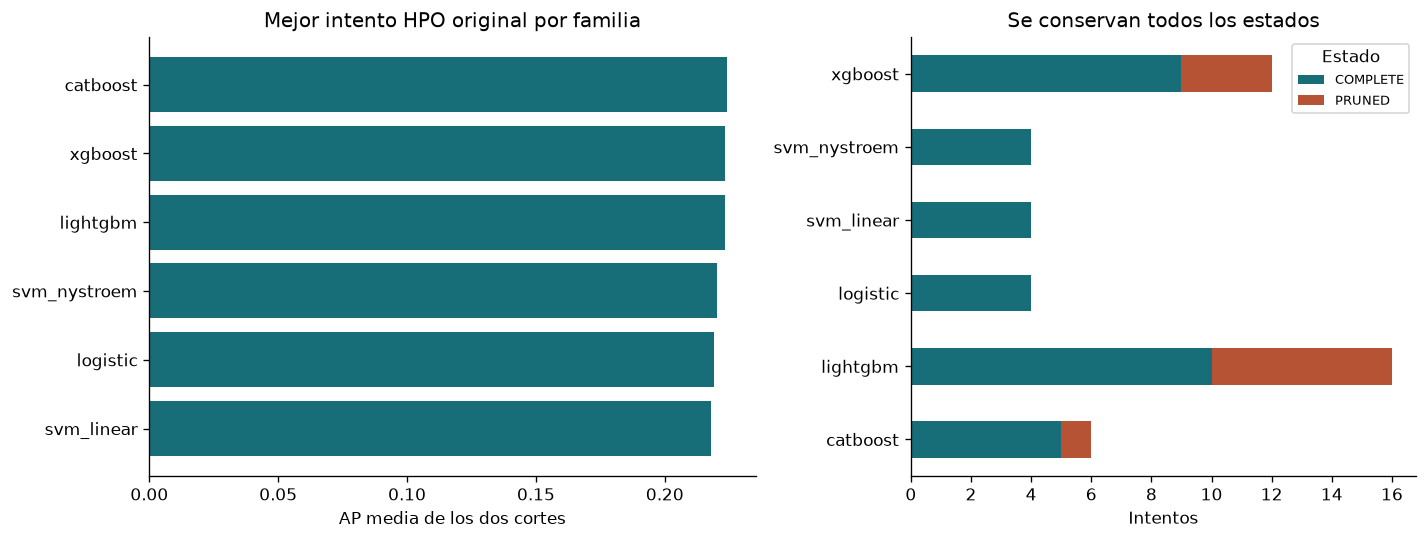

Comparaciones adicionales de preparación, fuera de los 46 intentos originales:


,family,status,baseline_CV_AP,log_clip_CV_AP,delta_AP,promoted
0,logistic,COMPLETE,0.218977,0.221054,0.002077,True
1,svm_linear,COMPLETE,0.218079,0.219468,0.001389,True
2,svm_nystroem,COMPLETE,0.220334,0.222127,0.001793,True


Configuraciones adicionales registradas: 3 ; conservadas para promoción: 3
Diferencias por corte, con hashes de entrenamiento y validación coincidentes:


,family,fold,baseline_AP,log_clip_AP,delta_AP,validation_n,same_ids_verified
0,logistic,1,0.213717,0.214079,0.000362,20000,True
1,logistic,2,0.224238,0.228029,0.003791,20000,True
2,svm_linear,1,0.213183,0.212625,-0.000558,20000,True
3,svm_linear,2,0.222975,0.226311,0.003336,20000,True
4,svm_nystroem,1,0.214153,0.214443,0.000289,20000,True
5,svm_nystroem,2,0.226514,0.229812,0.003297,20000,True


Familias con al menos un corte sin mejora positiva: ['svm_linear']
Promover por AP media no demuestra que la preparación mejore todos los períodos.


In [5]:
trial_tables = []
best_rows = []
for family in protocol['trials']:
    frame = read_table(f'search_{family}.csv')
    if not frame.empty:
        frame['family'] = family
        trial_tables.append(frame)
    best = read_json(f'best_{family}.json', [])
    for rank, item in enumerate(best, start=1):
        spec = item['spec']
        best_rows.append({'family': family, 'rank': rank, 'trial': item.get('trial_number'),
            'CV_AP': item['CV_AP'], 'feature_mode': spec['feature_mode'],
            'preparation': spec['preparation'], 'start': spec['start'],
            'half_life': spec['half_life'], 'params': spec['params'],
            'fold_AP': [fold['AP'] for fold in item['folds']]})
trials = pd.concat(trial_tables, ignore_index=True) if trial_tables else pd.DataFrame()
best_table = pd.DataFrame(best_rows)
if not trials.empty:
    states = pd.crosstab(trials['family'], trials['state'])
    display(states)
    print('Intentos HPO originales registrados:', len(trials), '; completos:', trials['state'].eq('COMPLETE').sum())
    rejected = trials.loc[~trials['state'].eq('COMPLETE')]
    if not rejected.empty:
        show_columns(rejected, ['family', 'number', 'state', 'value', 'duration',
            'params_feature_mode', 'params_preparation', 'params_start', 'params_half_life'])
if not best_table.empty:
    print('Mejores intentos de la búsqueda HPO original; las comparaciones adicionales de preparación se muestran por separado.')
    display(best_table.sort_values(['rank', 'CV_AP'], ascending=[True, False]))
    top = best_table.loc[best_table['rank'].eq(1)].sort_values('CV_AP')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.2, 1]})
    axes[0].barh(top['family'], top['CV_AP'], color=COLORS['positive'])
    axes[0].set(xlabel='AP media de los dos cortes', title='Mejor intento HPO original por familia')
    if not trials.empty:
        states.plot.barh(stacked=True, ax=axes[1], color=['#176D78', '#B75335', '#C7CCD5'][:len(states.columns)])
        axes[1].set(xlabel='Intentos', ylabel='', title='Se conservan todos los estados')
        axes[1].legend(title='Estado', fontsize=8)
    save_show(fig, '02_busqueda.png')
if (OUT / 'preparation_followup.csv').exists():
    preparation_followup = read_table('preparation_followup.csv')
    print('Comparaciones adicionales de preparación, fuera de los 46 intentos originales:')
    show_columns(preparation_followup, ['family', 'status', 'baseline_CV_AP',
        'log_clip_CV_AP', 'delta_AP', 'promoted'])
    print('Configuraciones adicionales registradas:', len(preparation_followup),
          '; conservadas para promoción:', int(preparation_followup['promoted'].eq(True).sum()))
    preparation_fold_rows = []
    for result in read_json('preparation_followup.json', []):
        if result['status'] != 'COMPLETE' or 'candidate' not in result:
            continue
        family = result['family']
        baseline_result = read_json(f'best_{family}.json', [])[0]
        baseline_folds = {fold['fold']: fold for fold in baseline_result['folds']}
        candidate_folds = {fold['fold']: fold for fold in result['candidate']['folds']}
        assert set(baseline_folds) == set(candidate_folds), f'Cortes distintos en {family}'
        for fold_id, candidate_fold in sorted(candidate_folds.items()):
            baseline_fold = baseline_folds[fold_id]
            for key in ['train_ids_sha256', 'validation_ids_sha256', 'train_n', 'validation_n']:
                assert baseline_fold[key] == candidate_fold[key], f'{family}, corte {fold_id}: cambió {key}'
            preparation_fold_rows.append({'family': family, 'fold': fold_id + 1,
                'baseline_AP': baseline_fold['AP'], 'log_clip_AP': candidate_fold['AP'],
                'delta_AP': candidate_fold['AP'] - baseline_fold['AP'],
                'validation_n': candidate_fold['validation_n'], 'same_ids_verified': True})
    preparation_by_fold = pd.DataFrame(preparation_fold_rows)
    if not preparation_by_fold.empty:
        print('Diferencias por corte, con hashes de entrenamiento y validación coincidentes:')
        display(preparation_by_fold)
        mixed = preparation_by_fold.groupby('family')['delta_AP'].apply(lambda values: not values.gt(0).all())
        print('Familias con al menos un corte sin mejora positiva:', mixed.index[mixed].tolist())
        print('Promover por AP media no demuestra que la preparación mejore todos los períodos.')

## 5. Selección posterior y ensambles

Se promueven los mejores intentos a entrenamiento completo hasta junio de 2014. El número de árboles se fija mediante la media de las mejores iteraciones de los cortes, multiplicada por 1,15 y limitada por el máximo buscado. El control V2 conserva sus parámetros originales. La validación completa de Q3 decide entre ellos.

**Ampliación adaptativa de desarrollo:** después de observar parte de la búsqueda y la auditoría del contexto se registró una [extensión al protocolo original](../experiments/development_followup_v3.json), antes de generar nuevas predicciones de 2015/2016. Añade **ocho candidatos**: dos controles CatBoost con los parámetros V2 y todas las mismas filas hasta junio —uno agrega contexto y otro contexto más relaciones financieras—, y seis combinaciones con el CatBoost V2, usando pesos V2 de 0,25, 0,50 y 0,75. Se mantiene el criterio de mayor AP sobre los mismos 40.595 préstamos de Q3.

La presencia de empleadores entre los textos laborales antiguos y de cargos entre los recientes motivó explorar heterogeneidad temporal; **no demuestra que el contexto vaya a mejorar la predicción**. La pérdida observada de AP del contexto en los cortes tempranos permanece registrada. Esta extensión no formaba parte del protocolo original y aumenta el optimismo potencial de la selección de desarrollo; no es una confirmación independiente ni autoriza escoger pesos con 2015/2016.

Un ensamble combina **predicciones**, no mezcla filas ni resultados reales. Si dos modelos asignan probabilidades distintas a un préstamo, una media ponderada produce una probabilidad combinada. Aquí se prueban pesos predefinidos, un promedio de tres familias de árboles y dos semillas de CatBoost. Los márgenes SVM se llevan a escala de probabilidad con una sigmoide aprendida a partir de predicciones de los cortes anteriores.

Los pesos ganadores se eligen en Q3. Este bloque es de selección, por lo que su mejor puntuación puede ser optimista. Si la combinación no mejora, se conserva el resultado y no se justifica usarla solo por ser más compleja.

registered_utc                                                                                         2026-11-02T21:17:35.621216+00:00
role                                Adaptive development-only extension; not part of the original search protocol and not an indepen...
observed_before_extension           [V3 LightGBM ablations and joint search, V3 CatBoost baseline AP early-stopping trial, developme...
new_benchmark_predictions_opened                                                                                                  False
controlled_models                   [{'name': 'catboost_context_control', 'feature_mode': 'context'}, {'name': 'catboost_combined_co...
additional_candidates                                                                                                                 8
selection_rule_unchanged            Highest raw AP on the identical Q3 development cohort; retain all prior candidates and all negat...
Name: Registro de la ampliación adaptativa de de

,model,type,AP,ROC_AUC,train_n,validation_n,train_ids_sha256,validation_ids_sha256,seconds
0,catboost_combined_control,single,0.256479,0.692325,215847.000000,40595,12a1c4aff39844fc028db5bd067b0de65af407dc47e29fc1ac21f0e20cbe524f,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,566.160000
1,blend_v2_catboost_combined_control_25,ensemble,0.256456,0.692928,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
2,blend_v2_catboost_combined_control_50,ensemble,0.255888,0.693081,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
3,blend_v2_svm_nystroem_joint_50,ensemble,0.255410,0.696282,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
4,blend_v2_svm_nystroem_joint_75,ensemble,0.255212,0.694799,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
5,blend_v2_logistic_joint_75,ensemble,0.255172,0.693104,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
6,blend_v2_svm_linear_joint_75,ensemble,0.255062,0.692860,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
7,blend_v2_catboost_combined_control_75,ensemble,0.254998,0.692796,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
8,blend_v2_logistic_joint_50,ensemble,0.254790,0.692613,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN
9,blend_v2_svm_linear_joint_50,ensemble,0.254699,0.692404,NaN,40595,NaN,3158e0d49385c66e87bf6064801c20ffaf14f8ada6f9c26129e45719f43c62a2,NaN


Estrategias comparadas en Q3: 39 = 13 modelos individuales + 26 ensambles.
Filas de validación compartidas: 40595
Elegido antes de generar nuevas predicciones de benchmark: catboost_combined_control
Pesos de los componentes: {'catboost_combined_control': 1.0}


,configuración
catboost_combined_control.family,catboost
catboost_combined_control.params.iterations,1177
catboost_combined_control.params.learning_rate,0.022056
catboost_combined_control.params.depth,7
catboost_combined_control.params.l2_leaf_reg,54.129934
catboost_combined_control.params.random_strength,1.972882
catboost_combined_control.params.bagging_temperature,0.609228
catboost_combined_control.params.rsm,0.684185
catboost_combined_control.params.auto_class_weights,None
catboost_combined_control.feature_mode,combined


Controles de variables: mismos parámetros CatBoost e IDs de entrenamiento y validación.


,model,AP,delta_AP_vs_v2,train_n,validation_n
0,v2_catboost,0.253568,0.000000,215847.000000,40595
1,catboost_context_control,0.253556,-0.000013,215847.000000,40595
2,catboost_combined_control,0.256479,0.002911,215847.000000,40595


El control combinado incorpora contexto y relaciones financieras juntos; su cambio total no se atribuye por separado a cada grupo ni a cada variable.
Mejor ensamble en Q3: blend_v2_catboost_combined_control_25, AP=0.25645635; AP de la estrategia elegida menos AP de ese ensamble: +0.00002243.
La diferencia es descriptiva del bloque de selección; no establece significación estadística.


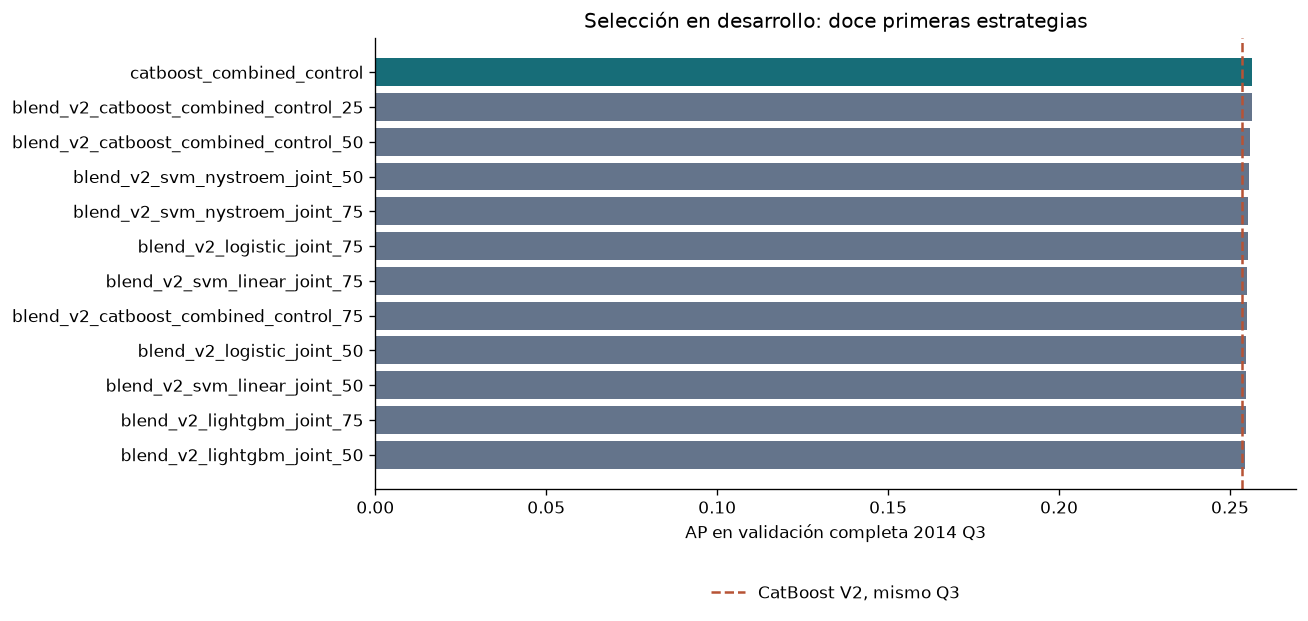

In [6]:
leaderboard = read_table('selection_leaderboard.csv')
followup_path = ROOT / 'experiments' / 'development_followup_v3.json'
if followup_path.exists():
    followup = json.loads(followup_path.read_text(encoding='utf-8'))
    display(pd.Series({key: followup.get(key) for key in [
        'registered_utc', 'role', 'observed_before_extension', 'new_benchmark_predictions_opened',
        'controlled_models', 'additional_candidates', 'selection_rule_unchanged']},
        name='Registro de la ampliación adaptativa de desarrollo'))
if not leaderboard.empty:
    display(leaderboard.sort_values('AP', ascending=False))
    assert leaderboard['validation_n'].nunique() == 1
    single_count = int(leaderboard['type'].eq('single').sum())
    ensemble_count = int(leaderboard['type'].eq('ensemble').sum())
    print(f'Estrategias comparadas en Q3: {len(leaderboard)} = '
          f'{single_count} modelos individuales + {ensemble_count} ensambles.')
    print('Filas de validación compartidas:', int(leaderboard['validation_n'].iloc[0]))
    print('Elegido antes de generar nuevas predicciones de benchmark:', selection['selected'])
    print('Pesos de los componentes:', selection['members'])
    chosen_specs = {name: selection['specs'][name] for name in selection['members']}
    display(pd.json_normalize(chosen_specs, sep='.').T.rename(columns={0: 'configuración'}))
    control_names = ['v2_catboost', 'catboost_context_control', 'catboost_combined_control']
    if set(control_names).issubset(set(leaderboard['model'])):
        controls = leaderboard.set_index('model').loc[control_names].copy()
        for key in ['train_ids_sha256', 'validation_ids_sha256', 'train_n', 'validation_n']:
            assert controls[key].nunique(dropna=False) == 1, f'Los controles CatBoost difieren en {key}'
        base_spec = selection['specs']['v2_catboost']
        for name in control_names[1:]:
            for key in ['family', 'params', 'start', 'half_life', 'seed', 'preparation']:
                assert selection['specs'][name][key] == base_spec[key], f'{name} difiere del control en {key}'
        controls['delta_AP_vs_v2'] = controls['AP'] - controls.loc['v2_catboost', 'AP']
        print('Controles de variables: mismos parámetros CatBoost e IDs de entrenamiento y validación.')
        show_columns(controls.reset_index(), ['model', 'AP', 'delta_AP_vs_v2', 'train_n', 'validation_n'])
        print('El control combinado incorpora contexto y relaciones financieras juntos; su cambio total no se atribuye por separado a cada grupo ni a cada variable.')
    ensemble_rows = leaderboard.loc[leaderboard['type'].eq('ensemble')]
    if not ensemble_rows.empty:
        best_ensemble = ensemble_rows.loc[ensemble_rows['AP'].idxmax()]
        chosen_ap = float(leaderboard.loc[leaderboard['model'].eq(selection['selected']), 'AP'].iloc[0])
        ensemble_gap = chosen_ap - float(best_ensemble['AP'])
        print(f"Mejor ensamble en Q3: {best_ensemble['model']}, AP={best_ensemble['AP']:.8f}; "
              f"AP de la estrategia elegida menos AP de ese ensamble: {ensemble_gap:+.8f}.")
        print('La diferencia es descriptiva del bloque de selección; no establece significación estadística.')
    top = leaderboard.nlargest(12, 'AP').sort_values('AP')
    fig, ax = plt.subplots(figsize=(11, 5.6))
    colors = [COLORS['positive'] if name == selection['selected'] else COLORS['reference'] for name in top['model']]
    ax.barh(top['model'], top['AP'], color=colors)
    old_row = leaderboard.loc[leaderboard['model'].eq('v2_catboost')]
    if not old_row.empty:
        ax.axvline(old_row['AP'].iloc[0], color=COLORS['negative'], linestyle='--', label='CatBoost V2, mismo Q3')
        ax.legend(loc='upper center', bbox_to_anchor=(.5, -.18), frameon=False)
    ax.set(xlabel='AP en validación completa 2014 Q3', title='Selección en desarrollo: doce primeras estrategias')
    save_show(fig, '03_seleccion_q3.png', layout_rect=(0, .04, 1, 1))

## 6. Resultado principal: comparación sobre exactamente la misma población

La tabla principal usa **258.856 préstamos de 2015 a 36 meses**, los mismos IDs del benchmark V2. Se compara contra el **CatBoost V2 congelado** y se mantiene separado el control que reutiliza sus parámetros con más meses de entrenamiento.

**No se compara con AP = 0,4164**, porque ese resultado anterior mezclaba plazos de 36 y 60 meses. Tampoco se interpreta una AP mayor en 2016 como una mejora del modelo respecto a 2015: cambia la población y su prevalencia. En cada año se comparan modelos sobre sus mismas filas.

`raw_AP` mide el ranking sin calibración; `AP` utiliza probabilidades calibradas cuando corresponda. `ROC_AUC` mide discriminación global y `Brier` evalúa el error de las probabilidades —menor es mejor—. `recall_at_top20` indica qué fracción de los incumplimientos aparece entre el 20% de préstamos con mayor riesgo estimado. Ninguna de estas cifras equivale directamente al beneficio económico de una política de crédito.

,model,n,prevalence,raw_AP,AP,ROC_AUC,Brier,precision,recall,recall_at_top20
2,catboost_combined_control,258856,0.148619,0.280128,0.280128,0.698253,0.118365,0.249594,0.582985,0.390944
4,lightgbm_joint,258856,0.148619,0.279396,0.279396,0.697692,0.118443,0.243606,0.611526,0.392062
7,svm_nystroem_joint,258856,0.148619,0.278102,0.278102,0.695873,0.118882,0.243035,0.619298,0.389046
8,v2_catboost,258856,0.148619,0.277484,0.277484,0.696322,0.118579,0.251714,0.566791,0.388786
9,xgboost_joint,258856,0.148619,0.275807,0.275807,0.695422,0.118712,0.279180,0.432170,0.388942
0,v2_frozen,258856,0.148619,0.275187,0.275187,0.695059,0.118769,0.253165,0.555119,0.386629
3,catboost_joint,258856,0.148619,0.274733,0.274733,0.693920,0.118793,0.262164,0.503366,0.386603
5,logistic_joint,258856,0.148619,0.272142,0.272142,0.691807,0.119014,0.244184,0.591225,0.384653
1,original_ensemble,258856,0.148619,0.271797,0.271797,0.691953,0.118993,0.282460,0.390918,0.382028
6,svm_linear_joint,258856,0.148619,0.271252,0.271252,0.691611,0.119073,0.235879,0.639677,0.383510


CatBoost V2 congelado: AP=0.275187
Selección V3: AP=0.280128; cambio=+0.004941 (+1.80% relativo).
El conjunto completo de cambios incluye fechas de entrenamiento y calibración; no se atribuye todo a hiperparámetros.


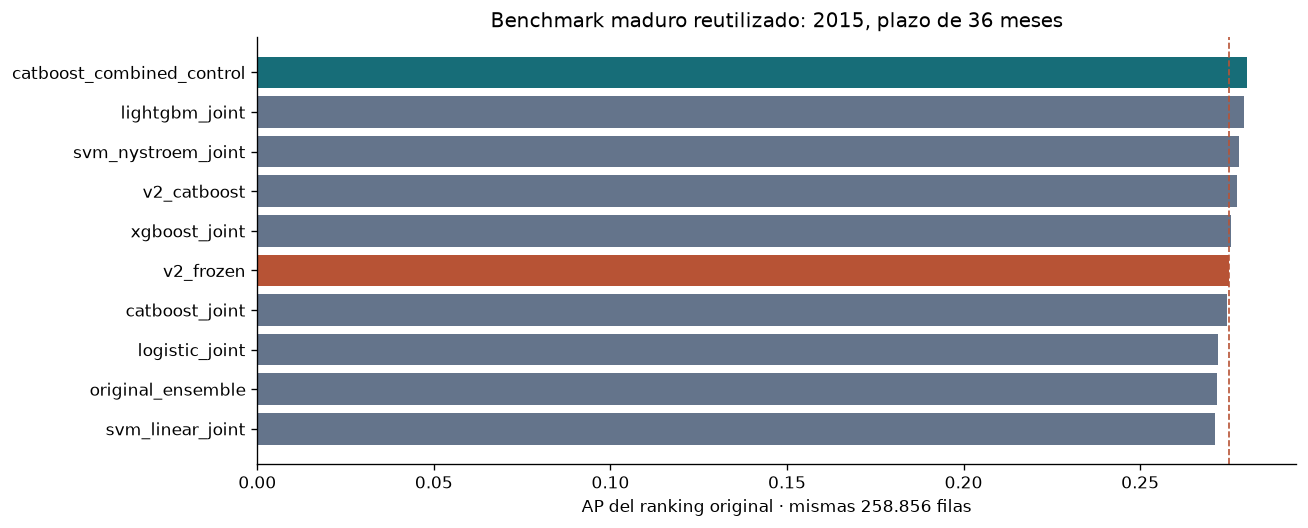

Comparación secundaria de 2016: estrés temporal condicionado a tener desenlace.


,model,n,prevalence,raw_AP,AP,ROC_AUC,Brier,recall_at_top20
10,v2_frozen,212482,0.198374,0.350974,0.350974,0.697325,0.150864,0.373870
11,original_ensemble,212482,0.198374,0.349501,0.349501,0.695192,0.150466,0.371972
12,catboost_combined_control,212482,0.198374,0.355980,0.355980,0.700276,0.149908,0.376005
13,catboost_joint,212482,0.198374,0.350808,0.350808,0.696459,0.150570,0.373562
14,lightgbm_joint,212482,0.198374,0.354749,0.354749,0.698670,0.150104,0.374606
15,logistic_joint,212482,0.198374,0.346575,0.346575,0.692310,0.151209,0.370169
16,svm_linear_joint,212482,0.198374,0.345548,0.345548,0.692041,0.151327,0.369386
17,svm_nystroem_joint,212482,0.198374,0.353974,0.353974,0.696756,0.150695,0.376551
18,v2_catboost,212482,0.198374,0.353529,0.353529,0.698880,0.150144,0.376385
19,xgboost_joint,212482,0.198374,0.350522,0.350522,0.696288,0.150489,0.371427


In [7]:
metric = ap_column(primary)
primary = primary.sort_values(metric, ascending=False)
show_columns(primary, ['model', 'n', 'prevalence', 'raw_AP', 'AP', 'ROC_AUC',
                       'Brier', 'precision', 'recall', 'recall_at_top20'])
baseline_ap = float(primary.loc[primary['model'].eq(reference_name), metric].iloc[0])
selected_ap = float(primary.loc[primary['model'].eq(selected_name), metric].iloc[0])
delta_ap = selected_ap - baseline_ap
relative_gain = 100 * delta_ap / baseline_ap
print(f'CatBoost V2 congelado: AP={baseline_ap:.6f}')
print(f'Selección V3: AP={selected_ap:.6f}; cambio={delta_ap:+.6f} ({relative_gain:+.2f}% relativo).')
print('El conjunto completo de cambios incluye fechas de entrenamiento y calibración; no se atribuye todo a hiperparámetros.')
fig, ax = plt.subplots(figsize=(11, max(4.5, .38 * len(primary))))
ordered = primary.sort_values(metric)
colors = [COLORS['positive'] if name == selected_name else
          COLORS['negative'] if name == reference_name else COLORS['reference'] for name in ordered['model']]
ax.barh(ordered['model'], ordered[metric], color=colors)
ax.axvline(baseline_ap, color=COLORS['negative'], linestyle='--', linewidth=1)
ax.set(xlabel='AP del ranking original · mismas 258.856 filas',
       title='Benchmark maduro reutilizado: 2015, plazo de 36 meses')
save_show(fig, '04_benchmark_2015.png')
print('Comparación secundaria de 2016: estrés temporal condicionado a tener desenlace.')
show_columns(benchmark.loc[benchmark['year'].eq('2016')],
    ['model', 'n', 'prevalence', 'raw_AP', 'AP', 'ROC_AUC', 'Brier', 'recall_at_top20'])

## 7. ¿La mejora se mantiene entre períodos?

Se examinan las diferencias entre el modelo seleccionado y el CatBoost V2 **dentro de cada período**, sin comparar directamente AP entre poblaciones distintas. Las filas por período deben coincidir para ambos modelos. Una mejora total no garantiza que todos los meses o trimestres mejoren.

Cuando está disponible, se vuelve a aplicar la estrategia ya elegida a los dos cortes anteriores con su configuración fijada. Es un diagnóstico sobre desarrollo reutilizado, posterior a la elección en Q3. Si un ensamble SVM necesita una transformación de probabilidades aprendida con etiquetas posteriores a esos cortes, no se reutiliza esa transformación para fingir una validación anterior: se registra la limitación.

El bootstrap pareado vuelve a muestrear resultados de ambos modelos juntos; el remuestreo por mes conserva parte de la estructura temporal. Sus intervalos son **condicionales al benchmark reutilizado**: no corrigen la historia completa de decisiones adaptativas, no restauran independencia y no garantizan rendimiento futuro.

La cohorte de 2016 tiene más préstamos sin desenlace en la fuente. Su resultado terminal se conserva como estrés temporal secundario y no se presenta como confirmación sobre todos los préstamos emitidos. Los años 2017/2018 tampoco crean una prueba madura por excluir sus préstamos activos.

Estrategia ya seleccionada sobre cortes anteriores: diagnóstico, no selección nueva.


,fold,period,model,n,AP,v2_AP,delta_AP_vs_v2,validation_ids_sha256,role
0,1,2013-07-01 / 2013-12-31,catboost_combined_control,20000,0.215490,0.216197,-0.000706,5025bc85d9cc5f06c6f7298de69a35ddd2d0ef88e3aa0cfc9e5a7e4a23a853d3,Reused development folds; selected after seeing Q3; diagnostic only
1,2,2014-01-01 / 2014-06-30,catboost_combined_control,20000,0.229425,0.231976,-0.002551,27e5aac14b3a95c715af10dbfdb5ad84dd100434258dafed4e1c5c76116561f5,Reused development folds; selected after seeing Q3; diagnostic only


Cortes anteriores con ΔAP positiva: 0 de 2


,cohort,period,model,n,positive_n,prevalence,AP,ROC_AUC,Brier,log_loss,...,flag_rate,FPR,FNR,KS,recall_at_top20,precision_at_top20,raw_AP,raw_ROC_AUC,calibration_AP_preserved,delta_AP_vs_v2
0,2015,2015Q1,v2_frozen,51704,7637,0.147706,0.264443,0.689572,0.118739,0.389966,...,0.342121,0.302812,0.431059,0.280684,0.379861,0.280534,0.264443,0.689572,True,0.000000
1,2015,2015Q1,original_ensemble,51704,7637,0.147706,0.262236,0.685807,0.119035,0.391048,...,0.219906,0.188259,0.597486,0.277905,0.374100,0.276279,0.262236,0.685807,True,-0.002207
2,2015,2015Q1,catboost_combined_control,51704,7637,0.147706,0.269432,0.692708,0.118400,0.388824,...,0.364633,0.324165,0.401859,0.283523,0.383266,0.283048,0.269432,0.692708,True,0.004989
3,2015,2015Q1,catboost_joint,51704,7637,0.147706,0.264343,0.687689,0.118846,0.390441,...,0.300422,0.263440,0.486186,0.282705,0.377766,0.278987,0.264343,0.687689,True,-0.000101
4,2015,2015Q1,lightgbm_joint,51704,7637,0.147706,0.269090,0.691639,0.118488,0.389208,...,0.391362,0.350489,0.372790,0.285263,0.381563,0.281791,0.269090,0.691639,True,0.004647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,2016,2016Q4,logistic_joint,41204,8816,0.213960,0.350299,0.680725,0.163614,0.507471,...,0.344505,0.290848,0.458371,0.262972,0.353221,0.377867,0.350299,0.680725,True,-0.010186
76,2016,2016Q4,svm_linear_joint,41204,8816,0.213960,0.349301,0.680211,0.163757,0.507883,...,0.388700,0.333827,0.409710,0.264247,0.350499,0.374954,0.349301,0.680211,True,-0.011184
77,2016,2016Q4,svm_nystroem_joint,41204,8816,0.213960,0.358135,0.685986,0.163173,0.506245,...,0.372173,0.316166,0.422074,0.272489,0.359574,0.384662,0.358135,0.685986,True,-0.002350
78,2016,2016Q4,v2_catboost,41204,8816,0.213960,0.361594,0.689004,0.162153,0.503242,...,0.323003,0.268587,0.477087,0.276274,0.360594,0.385754,0.361594,0.689004,True,0.001109


model,cohort,period,catboost_combined_control,v2_frozen,delta_AP
0,2015,2015Q1,0.269432,0.264443,0.004989
1,2015,2015Q2,0.287002,0.280395,0.006607
2,2015,2015Q3,0.279251,0.274733,0.004518
3,2015,2015Q4,0.283505,0.279318,0.004187
4,2016,2016Q1,0.311695,0.305541,0.006153
5,2016,2016Q2,0.394977,0.390096,0.004880
6,2016,2016Q3,0.397675,0.392429,0.005246
7,2016,2016Q4,0.363643,0.360485,0.003158


Mejora en 8 de 8 períodos registrados; no se ocultan cambios negativos.


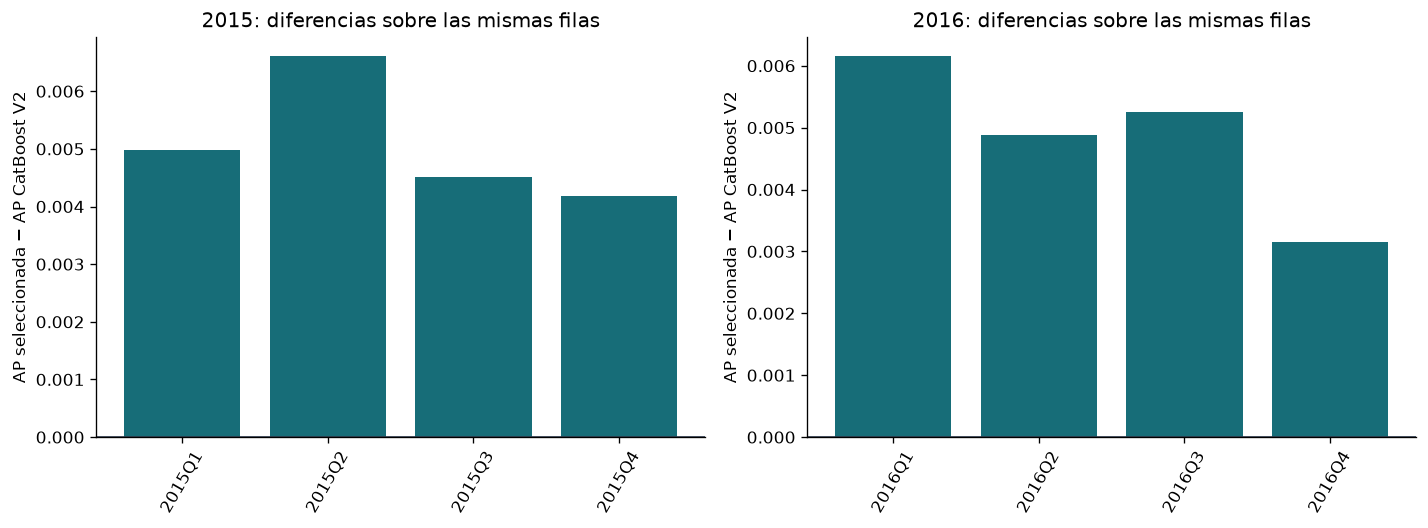

,valor
2015_36_vs_v2_frozen.row.AP.low,0.276013
2015_36_vs_v2_frozen.row.AP.high,0.284607
2015_36_vs_v2_frozen.row.ROC_AUC.low,0.695347
2015_36_vs_v2_frozen.row.ROC_AUC.high,0.701218
2015_36_vs_v2_frozen.row.Brier.low,0.117550
2015_36_vs_v2_frozen.row.Brier.high,0.119192
2015_36_vs_v2_frozen.row.paired_AP_delta_vs_baseline.low,0.003922
2015_36_vs_v2_frozen.row.paired_AP_delta_vs_baseline.high,0.006109
2015_36_vs_v2_frozen.row.repetitions,300
2015_36_vs_v2_frozen.issue_month_block.AP.low,0.273158


IC bootstrap condicional del 95% de ΔAP, por bloques de mes: [+0.003767, +0.006188].


In [8]:
stability = read_table('temporal_stability.csv')
if not stability.empty:
    print('Estrategia ya seleccionada sobre cortes anteriores: diagnóstico, no selección nueva.')
    display(stability)
    print('Cortes anteriores con ΔAP positiva:', int(stability['delta_AP_vs_v2'].gt(0).sum()),
          'de', len(stability))
stability_limit = read_json('temporal_stability_limitation.json', {})
if stability_limit:
    display(pd.Series(stability_limit, name='Límite de la revisión temporal anterior'))
periods = read_table('benchmark_periods.csv')
period_deltas = pd.DataFrame()
if not periods.empty:
    display(periods)
    period_key = next((c for c in ['period', 'quarter', 'issue_quarter', 'issue_month', 'month'] if c in periods), None)
    if period_key is not None and {reference_name, selected_name}.issubset(set(periods['model'])):
        period_metric = ap_column(periods)
        index_cols = ['cohort', period_key] if 'cohort' in periods else [period_key]
        subset = periods.loc[periods['model'].isin([reference_name, selected_name])]
        values = subset.pivot(index=index_cols, columns='model', values=period_metric).dropna()
        counts = subset.pivot(index=index_cols, columns='model', values='n').loc[values.index]
        assert counts[reference_name].eq(counts[selected_name]).all()
        values['delta_AP'] = values[selected_name] - values[reference_name]
        period_deltas = values.reset_index()
        display(period_deltas)
        positive = int(period_deltas['delta_AP'].gt(0).sum())
        print(f'Mejora en {positive} de {len(period_deltas)} períodos registrados; no se ocultan cambios negativos.')
        if 'cohort' in period_deltas:
            period_deltas['year'] = cohort_year(period_deltas)
        else:
            period_deltas['year'] = period_deltas[period_key].astype(str).str[:4]
        years = sorted(period_deltas['year'].dropna().unique())
        fig, axes = plt.subplots(1, len(years), figsize=(max(8, 6 * len(years)), 4.5), squeeze=False)
        for ax, year in zip(axes[0], years):
            group = period_deltas.loc[period_deltas['year'].eq(year)].sort_values(period_key)
            ax.bar(group[period_key].astype(str), group['delta_AP'],
                   color=[COLORS['positive'] if x > 0 else COLORS['negative'] for x in group['delta_AP']])
            ax.axhline(0, color='#334155', linewidth=1)
            ax.tick_params(axis='x', rotation=60)
            ax.set(ylabel='AP seleccionada − AP CatBoost V2', title=f'{year}: diferencias sobre las mismas filas')
        save_show(fig, '05_estabilidad_temporal.png')
uncertainty = read_json('benchmark_uncertainty.json', {})
paired_month_interval = None
if uncertainty:
    display(pd.json_normalize(uncertainty, sep='.').T.rename(columns={0: 'valor'}))
    primary_uncertainty = uncertainty.get('2015_36_vs_v2_frozen', {})
    paired_month_interval = primary_uncertainty.get('issue_month_block', {}).get('paired_AP_delta_vs_baseline')
    if paired_month_interval is not None:
        print(f"IC bootstrap condicional del 95% de ΔAP, por bloques de mes: "
              f"[{paired_month_interval['low']:+.6f}, {paired_month_interval['high']:+.6f}].")
else:
    print('No se dispone de un intervalo de incertidumbre registrado; no se inventa uno.')

## 8. Errores, umbrales y probabilidades

Se revisan segmentos de FICO, ingresos y demás dimensiones registradas para detectar dónde se concentran los errores. **FNR** es la proporción de incumplimientos que el umbral deja pasar; **FPR** es la proporción de préstamos pagados que marca como riesgosos. Cambiar el umbral mueve ambos errores y no cambia el ranking subyacente.

Los umbrales V3 se fijaron con la parte reservada de diciembre. El modelo V2 conserva su procedimiento anterior: una diferencia de FNR/FPR puede combinar cambios de ranking, calibración y política de umbral. Para el ranking se mantiene AP y la revisión del 20% con mayor riesgo. Segmentos pequeños o con pocos incumplimientos pueden producir estimaciones inestables; deben leerse junto con su tamaño.

La calibración busca probabilidades más coherentes con la frecuencia de incumplimiento; no añade información al ranking. Una sigmoide de pendiente positiva conserva el orden salvo posibles empates numéricos. Por ello `raw_AP` permanece como criterio principal.

In [9]:
segments = read_table('benchmark_segment_errors.csv')
if not segments.empty:
    focus = segments.loc[segments['model'].isin([reference_name, selected_name])].copy()
    if 'cohort' in focus:
        focus = focus.loc[cohort_year(focus).eq('2015')]
    show_columns(focus, ['cohort', 'model', 'dimension', 'segment', 'n', 'prevalence',
        'raw_AP', 'AP', 'precision', 'recall', 'FNR', 'FPR', 'low_support'])
    if 'low_support' in focus:
        print('Filas de segmentos marcadas con soporte insuficiente:', int(focus['low_support'].eq(True).sum()))
if not calibration.empty:
    print('Calibración y umbrales: bloques y tamaños registrados, sin ajuste en el benchmark.')
    display(calibration)

,cohort,model,dimension,segment,n,prevalence,raw_AP,AP,precision,recall,FNR,FPR
0,2015,catboost_combined_control,home_ownership,MORTGAGE,118679,0.120603,0.237300,0.237300,0.232653,0.455879,0.544121,0.206207
1,2015,v2_frozen,home_ownership,MORTGAGE,118679,0.120603,0.233147,0.233147,0.236745,0.425208,0.574792,0.188002
2,2015,catboost_combined_control,home_ownership,OWN,29124,0.158495,0.280746,0.280746,0.244788,0.602903,0.397097,0.350335
3,2015,v2_frozen,home_ownership,OWN,29124,0.158495,0.272557,0.272557,0.245999,0.576040,0.423960,0.332544
4,2015,catboost_combined_control,home_ownership,RENT,111052,0.175972,0.306885,0.306885,0.260096,0.671374,0.328626,0.407857
...,...,...,...,...,...,...,...,...,...,...,...,...
143,2015,v2_frozen,annual_income,"[40000.0, 60000.0)",69529,0.159142,0.279558,0.279558,0.247834,0.602350,0.397650,0.345991
144,2015,catboost_combined_control,annual_income,"[60000.0, 80000.0)",56148,0.143371,0.277410,0.277410,0.256343,0.525839,0.474161,0.255312
145,2015,v2_frozen,annual_income,"[60000.0, 80000.0)",56148,0.143371,0.270953,0.270953,0.261119,0.487205,0.512795,0.230737
146,2015,catboost_combined_control,annual_income,"[80000.0, 120000.0)",53393,0.120671,0.250710,0.250710,0.251107,0.422474,0.577526,0.172907


Calibración y umbrales: bloques y tamaños registrados, sin ajuste en el benchmark.


,model,method,calibration_n,sigmoid_slope,sigmoid_intercept,n,positive_n,prevalence,AP,ROC_AUC,...,threshold,flag_rate,FPR,FNR,KS,recall_at_top20,precision_at_top20,raw_AP,raw_ROC_AUC,calibration_AP_preserved
0,catboost_combined_control,positive_sigmoid,3371,1.096570,0.175113,3503,491,0.140166,0.281141,0.707184,...,0.159726,0.328576,0.287185,0.417515,0.311099,0.399185,0.279601,0.281141,0.707184,True
1,catboost_joint,positive_sigmoid,3371,1.139414,0.269655,3503,491,0.140166,0.277813,0.702253,...,0.177776,0.263203,0.225432,0.505092,0.303775,0.391039,0.273894,0.277813,0.702253,True
2,lightgbm_joint,positive_sigmoid,3371,1.057146,0.127194,3503,491,0.140166,0.289415,0.705427,...,0.151004,0.343134,0.303121,0.411405,0.307120,0.397149,0.278174,0.289415,0.705427,True
3,logistic_joint,positive_sigmoid,3371,0.969604,-0.017419,3503,491,0.140166,0.282951,0.702547,...,0.154074,0.336283,0.294821,0.409369,0.297853,0.399185,0.279601,0.282951,0.702547,True
4,svm_linear_joint,positive_sigmoid,3371,2.121787,-1.829863,3503,491,0.140166,0.280582,0.702713,...,0.143408,0.384528,0.342961,0.360489,0.296550,0.395112,0.276748,0.280582,0.702713,True
5,svm_nystroem_joint,positive_sigmoid,3371,3.966861,0.926798,3503,491,0.140166,0.280178,0.707051,...,0.139890,0.353982,0.312417,0.391039,0.309023,0.399185,0.279601,0.280178,0.707051,True
6,v2_catboost,positive_sigmoid,3371,1.117880,0.229507,3503,491,0.140166,0.281242,0.705674,...,0.162536,0.311162,0.270584,0.439919,0.302651,0.393075,0.275321,0.281242,0.705674,True
7,xgboost_joint,positive_sigmoid,3371,1.088096,-0.561218,3503,491,0.140166,0.283588,0.707203,...,0.196636,0.209535,0.172643,0.564155,0.302933,0.421589,0.295292,0.283588,0.707203,True


## 9. Interpretabilidad del predictor

Esta importancia corresponde a los **modelos candidatos de la estrategia seleccionada, entrenados hasta junio de 2014**, evaluados en una muestra estratificada de **6.000 préstamos de Q3**, con semilla 42 y **tres permutaciones por grupo**. Su alcance es el predictor de desarrollo; el reajuste final hasta noviembre se evalúa en el benchmark posterior.

Se altera un grupo de entradas y se mide cuánto cae AP manteniendo fijo el modelo. Todas las columnas de un grupo reciben la misma permutación y las relaciones financieras se recalculan a partir de las entradas modificadas. Una caída mayor indica mayor dependencia predictiva en este conjunto de desarrollo.

Esta importancia **no demuestra que una variable cause el incumplimiento**. Predictores correlacionados pueden compartir señal, y una caída negativa pequeña puede aparecer por ruido. La tabla muestra el tamaño de evaluación y la dispersión de repeticiones cuando están disponibles. El análisis posterior no se utiliza para volver a seleccionar el modelo.

selected                                                                                           catboost_combined_control
model_stage                                     Q3 candidates trained through June 2014; final November models are not used.
validation_start                                                                                                  2014-07-01
validation_end                                                                                                    2014-09-30
complete_validation_n                                                                                                  40595
validation_n                                                                                                            6000
sampling                                                                    Stratified sample_development, cap=6000, seed=42
permutations                                                                                                               3


,feature_group,mean_AP_drop,permutation_sd,validation_n,baseline_AP,permutations,raw_columns,AP_drop_1,AP_drop_2,AP_drop_3
0,bureau_accounts,0.046092,0.002364,6000,0.265357,3,open_acc|total_acc|tot_cur_bal|total_bal_ex_mort|tot_hi_cred_lim|avg_cur_bal|open_acc_6m|open_ac...,0.046962,0.047899,0.043417
1,revolving,0.038654,0.006530,6000,0.265357,3,revol_bal|revol_util|total_rev_hi_lim|bc_open_to_buy|bc_util|total_bc_limit|max_bal_bc|all_util|...,0.041654,0.031163,0.043143
2,loan_amount,0.037691,0.012884,6000,0.265357,3,loan_amnt,0.022830,0.045704,0.044540
3,income,0.018265,0.000923,6000,0.265357,3,annual_inc|annual_inc_joint,0.017971,0.019299,0.017524
4,FICO,0.015974,0.000654,6000,0.265357,3,fico_range_low|fico_range_high,0.016672,0.015377,0.015872
5,credit_history,0.012556,0.001078,6000,0.265357,3,earliest_cr_line|mo_sin_old_il_acct|mo_sin_old_rev_tl_op|mo_sin_rcnt_rev_tl_op|mo_sin_rcnt_tl|mt...,0.013358,0.012979,0.011331
6,homepurpose,0.010876,0.002967,6000,0.265357,3,home_ownership|purpose|verification_status|application_type|addr_state,0.014153,0.010103,0.008373
7,dti,0.010539,0.004874,6000,0.265357,3,dti|dti_joint,0.006086,0.009785,0.015746
8,delinquency,0.006047,0.000812,6000,0.265357,3,delinq_2yrs|pub_rec|mths_since_last_delinq|mths_since_last_record|mths_since_last_major_derog|co...,0.006787,0.005179,0.006176
9,context_zip,0.000430,0.000285,6000,0.265357,3,zip_code,0.000518,0.000112,0.000661


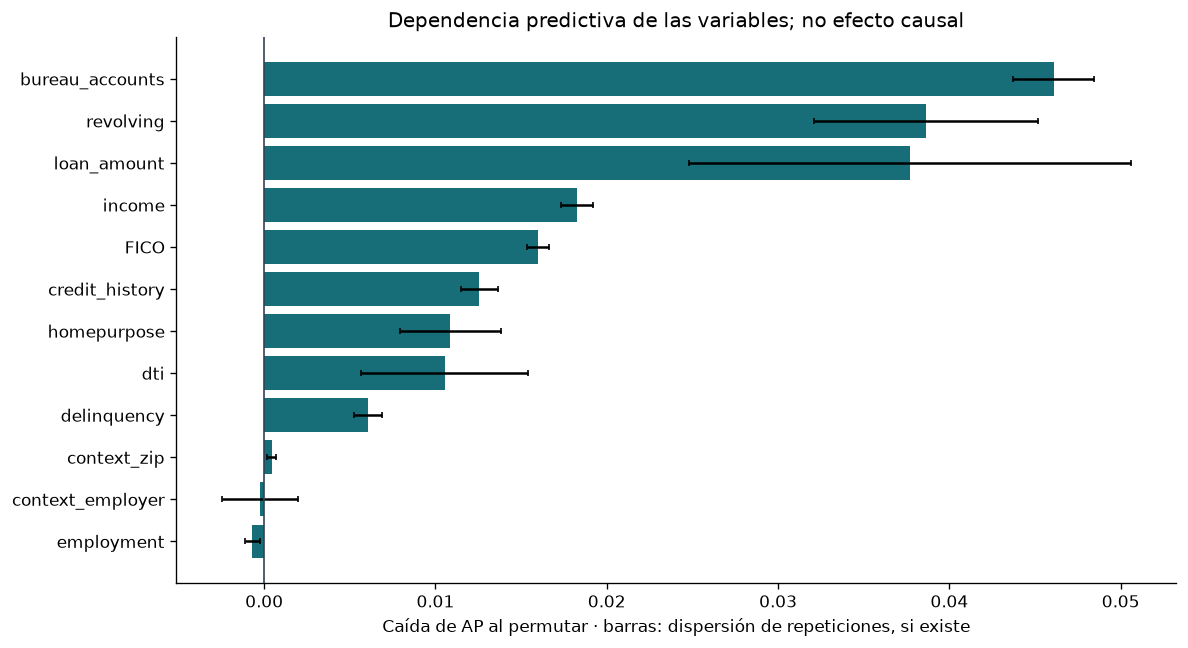

In [10]:
interpretation_scope = read_json('interpretability_scope.json', {})
if interpretation_scope:
    display(pd.Series({key: interpretation_scope.get(key) for key in [
        'selected', 'model_stage', 'validation_start', 'validation_end',
        'complete_validation_n', 'validation_n', 'sampling', 'permutations', 'role', 'limits']},
        name='Alcance de la interpretación del predictor de desarrollo'))
importance = read_table('interpretability.csv')
if not importance.empty:
    display(importance)
    name_col = next((c for c in ['feature_group', 'feature', 'variable'] if c in importance), None)
    value_col = next((c for c in ['mean_AP_drop', 'AP_drop', 'importance_mean'] if c in importance), None)
    if name_col is not None and value_col is not None:
        plot = importance.copy()
        if 'model' in plot and selected_name in set(plot['model']):
            plot = plot.loc[plot['model'].eq(selected_name)]
        plot = plot.nlargest(15, value_col).sort_values(value_col)
        error_col = next((c for c in ['permutation_sd', 'std_AP_drop', 'importance_std'] if c in plot), None)
        errors = plot[error_col].fillna(0) if error_col is not None else None
        fig, ax = plt.subplots(figsize=(10, 5.5))
        ax.barh(plot[name_col], plot[value_col], xerr=errors, color=COLORS['positive'], capsize=2)
        ax.axvline(0, color='#334155', linewidth=1)
        ax.set(xlabel='Caída de AP al permutar · barras: dispersión de repeticiones, si existe',
               title='Dependencia predictiva de las variables; no efecto causal')
        save_show(fig, '06_interpretabilidad.png')

## 10. Balance de la investigación y resultados que no mejoraron

La conclusión se calcula a partir de los artefactos, sin asumir que una nueva familia o un ensamble debe ganar. Las ablaciones distinguen los cambios individuales del cambio conjunto `combined`; la selección Q3 decide la estrategia; el benchmark conocido contrasta el resultado posterior. Si los signos varían entre períodos, no se afirma una mejora uniforme.

Para una **prueba final realmente independiente** hacen falta desenlaces maduros y no utilizados, además de información fiable sobre cuándo estuvieron disponibles. Volver a dividir préstamos ya observados, escoger los casos terminados de 2017/2018 o cambiar de población no resuelve esa necesidad.

In [11]:
if delta_ap > 0:
    print(f'La estrategia seleccionada supera puntualmente al CatBoost V2 en el benchmark 2015: ΔAP={delta_ap:+.6f}.')
    print('Es una mejora observada en una evaluación reutilizada, no una confirmación independiente nueva.')
elif delta_ap < 0:
    print(f'La estrategia seleccionada no supera al CatBoost V2 en 2015: ΔAP={delta_ap:+.6f}.')
    print('Se conserva este resultado negativo. Elegir retrospectivamente otro finalista por esta tabla usaría de nuevo el benchmark para selección.')
else:
    print('La estrategia seleccionada y el CatBoost V2 empatan en AP en esta evaluación.')
if paired_month_interval is not None:
    if paired_month_interval['low'] > 0:
        print('El intervalo pareado por meses queda por encima de cero bajo este remuestreo condicional; la reutilización impide tratarlo como confirmación independiente.')
    elif paired_month_interval['high'] < 0:
        print('El intervalo pareado por meses queda por debajo de cero: este remuestreo condicional respalda una pérdida de AP frente a V2.')
    else:
        print('El intervalo pareado por meses incluye cero: no se distingue una ganancia positiva bajo este criterio de incertidumbre.')
if not stability.empty:
    earlier_gains = stability['delta_AP_vs_v2'].gt(0)
    print(f"Cortes anteriores de desarrollo con ΔAP positiva: {earlier_gains.sum()} de {len(stability)}; son desarrollo reutilizado.")
if not period_deltas.empty:
    gains = period_deltas['delta_AP'].gt(0)
    benchmark_years = ', '.join(sorted(period_deltas['year'].dropna().astype(str).unique()))
    if gains.all():
        print(f'ΔAP es positiva en los {len(gains)} trimestres evaluados del benchmark ({benchmark_years}); '
              'esta afirmación se limita a esos trimestres y a sus poblaciones observadas.')
    else:
        print(f'En el benchmark ({benchmark_years}), {(~gains).sum()} de {len(gains)} trimestres '
              'no presentan ganancia positiva de AP.')
if not stability.empty and not earlier_gains.all():
    print(f'La revisión anterior conserva {(~earlier_gains).sum()} de {len(earlier_gains)} cortes '
          'sin mejora positiva; el resultado no es uniforme en toda la historia.')
if not ablations.empty:
    negatives = ablations.loc[~ablations['name'].eq('baseline') & ablations['delta_AP'].le(0)]
    print('Intervenciones que no mejoraron AP media en la ablación controlada:')
    display(negatives[['name', 'CV_AP', 'delta_AP']])
if not leaderboard.empty:
    reference_q3 = leaderboard.loc[leaderboard['model'].eq('v2_catboost'), 'AP']
    if not reference_q3.empty:
        rejected_ensembles = leaderboard.loc[leaderboard['type'].eq('ensemble') &
                                             leaderboard['AP'].le(reference_q3.iloc[0])]
        print('Ensambles que no superaron al control V2 en la validación Q3:')
        display(rejected_ensembles[['model', 'AP']])
print('La tabla completa también conserva modelos perdedores, intentos podados y configuraciones fallidas.')
print('No se ha demostrado el mejor modelo posible ni una mejora garantizada fuera de estas cohortes.')
verification = read_json('verification.json', {})
if verification:
    display(pd.Series({key: verification.get(key) for key in
        ['verified_utc', 'check_count', 'all_checks_passed', 'role']},
        name='Verificación científica registrada'))
    print('Las huellas actualizadas de los archivos se consultan en outputs/research_v3/verification.json; no se incrusta la huella del propio notebook.')
receipt = read_json('benchmark_receipt.json', {})
if receipt:
    display(pd.Series(receipt, name='Recibo de evaluación'))

La estrategia seleccionada supera puntualmente al CatBoost V2 en el benchmark 2015: ΔAP=+0.004941.
Es una mejora observada en una evaluación reutilizada, no una confirmación independiente nueva.
El intervalo pareado por meses queda por encima de cero bajo este remuestreo condicional; la reutilización impide tratarlo como confirmación independiente.
Cortes anteriores de desarrollo con ΔAP positiva: 0 de 2; son desarrollo reutilizado.
ΔAP es positiva en los 8 trimestres evaluados del benchmark (2015, 2016); esta afirmación se limita a esos trimestres y a sus poblaciones observadas.
La revisión anterior conserva 2 de 2 cortes sin mejora positiva; el resultado no es uniforme en toda la historia.
Intervenciones que no mejoraron AP media en la ablación controlada:


,name,CV_AP,delta_AP
1,financial,0.221962,-0.000651
2,context,0.211609,-0.011004
3,combined,0.213912,-0.008701
4,clipping,0.221238,-0.001375
5,from_2013,0.219008,-0.003605
6,recency12,0.220620,-0.001993
7,recency24,0.222422,-0.000191


Ensambles que no superaron al control V2 en la validación Q3:


,model,AP
21,blend_v2_lightgbm_joint_25,0.253061
22,blend_v2_catboost_joint_75,0.252972
23,three_tree_families,0.252940
24,blend_v2_svm_linear_joint_25,0.252787
25,blend_v2_logistic_joint_25,0.252690
26,blend_v2_xgboost_joint_25,0.252581
28,blend_v2_catboost_joint_50,0.252213
29,blend_v2_catboost_joint_25,0.251312
33,catboost_two_seeds,0.250528


La tabla completa también conserva modelos perdedores, intentos podados y configuraciones fallidas.
No se ha demostrado el mejor modelo posible ni una mejora garantizada fuera de estas cohortes.


verified_utc                                                               2026-11-02T23:41:56.136488+00:00
check_count                                                                                              68
all_checks_passed                                                                                      True
role                 Artifact and calculation verification; it does not make reused benchmarks independent.
Name: Verificación científica registrada, dtype: object

Las huellas actualizadas de los archivos se consultan en outputs/research_v3/verification.json; no se incrusta la huella del propio notebook.


state                                                                                                                  complete
started_utc                                                                                    2026-11-02T23:29:52.267761+00:00
completed_utc                                                                                  2026-11-02T23:34:11.946212+00:00
role                        Previously observed, reused retrospective benchmarks. NOT a new independent final test. No tunin...
lock_sha256                                                    1417c2093e9e46eb1a6d9d1927436a56156e2e7d30168baf2374ce1343cbe9ec
selected                                                                                              catboost_combined_control
selected_model_unchanged                                                                                                   True
metrics_sha256                                                 377b63e0ad538a963d7a477a7a69e2b3a4b260939

## Reproducción y referencias

Este notebook lee los artefactos ya calculados; ejecutarlo no entrena modelos. El protocolo, los intentos y los archivos de selección conservan las decisiones. Los modelos y predicciones individuales se almacenan localmente conforme a `.gitignore`; los CSV/JSON agregados y este notebook documentan el resultado.

Para repetir la investigación desde los datos preparados, revisar primero [el protocolo V3](../experiments/protocol_v3.json) y la interfaz `python -m optimization.experiments --help`. Cada etapa conserva trazabilidad. La protección del benchmark impide continuar ajustando sobre un directorio cuya evaluación ya se abrió; una reproducción debe usar otro directorio de salida. Repetir el entrenamiento completo exige tiempo de CPU y el archivo fuente local.

- [Definición de Average Precision — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- [Calibración y conservación del ranking — scikit-learn](https://scikit-learn.org/stable/modules/calibration.html).
- [Métricas de clasificación — CatBoost](https://catboost.ai/docs/en/concepts/loss-functions-classification).
- [CatBoost: tratamiento de categorías y sesgo de predicción — artículo original](https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html).
- [Parámetros de LightGBM — documentación oficial](https://lightgbm.readthedocs.io/en/stable/Parameters.html).

Estos fundamentos orientan las hipótesis; las tablas de este proyecto determinan cuáles aportaron mejora sobre sus datos.